# Digital Advertising Budget Optimizer
## Notebook 05 — Benchmark: Pandas vs MapReduce vs Spark

**Question:** as the data grows from 10K to 10M rows, which tool computes the platform KPIs fastest, and where does each one hit its limits?

**Fair-test rules**
| Rule | Why |
|---|---|
| Same task for every engine: read the CSV → group by platform → sum 5 metrics | Like-for-like work |
| Same input: the CSV files from Notebook 01 | MapReduce can only read text, so CSV is the common format |
| Same machine, same session, engines interleaved | No engine gets a faster VM or a quieter moment |
| Warm-up run first, then 3 timed repetitions; median reported | Removes one-off start-up noise |
| Files pre-loaded into the OS cache | Every engine reads from memory, not a cold disk |
| Every run's answer checked against a reference | A fast wrong answer doesn't count |

**What the timer includes:** reading + aggregating. Pandas runs in a fresh process each time (so its memory can be measured);
Spark reuses a running session (normal for Spark); each MapReduce job starts its own JVM (normal for Hadoop).

**Requires:** Notebooks 01–04 completed. Runtime ~10–15 min.

In [1]:
# ============================================================
# 1. Setup
# ============================================================
import os, sys, shutil, time, json, re, glob, subprocess, platform, warnings
from pathlib import Path
warnings.filterwarnings("ignore", category=FutureWarning)

try:
    from google.colab import drive
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

PROJECT_NAME = "ad-budget-optimizer"
if IN_COLAB:
    drive.mount("/content/drive")
    DRIVE_DIR = Path("/content/drive/MyDrive") / PROJECT_NAME
    LOCAL_DIR = Path("/content") / PROJECT_NAME
else:
    DRIVE_DIR = LOCAL_DIR = Path.cwd() / PROJECT_NAME

SRC_DIR = DRIVE_DIR / "src"
BENCH_SRC = SRC_DIR / "bench"
FIG_DIR, REP_DIR, BENCH_DIR = (DRIVE_DIR / "outputs" / d for d in ("figures", "reports", "benchmarks"))
for d in (BENCH_SRC, FIG_DIR, REP_DIR, BENCH_DIR):
    d.mkdir(parents=True, exist_ok=True)
sys.path.insert(0, str(SRC_DIR))
assert (SRC_DIR / "mapreduce/mapper.py").exists(), "Run Notebook 03 first (it creates the MapReduce scripts)."

REPEATS = 3
SCALES = {"10k": 10_000, "100k": 100_000, "1m": 1_000_000, "10m": 10_000_000}
if (DRIVE_DIR / "data/raw/csv/ads_50m.csv").exists():          # stress tier from Notebook 01, if generated
    SCALES["50m"] = 50_000_000
reps_for = lambda label: 1 if SCALES[label] > 10_000_000 else REPEATS

RAW_LOCAL = LOCAL_DIR / "data/raw"
for label in SCALES:
    for sub, name in (("csv", f"ads_{label}.csv"), ("parquet", f"ads_{label}")):
        src_p, dst_p = DRIVE_DIR / "data/raw" / sub / name, RAW_LOCAL / sub / name
        if not dst_p.exists():
            dst_p.parent.mkdir(parents=True, exist_ok=True)
            t0 = time.time()
            (shutil.copytree if src_p.is_dir() else shutil.copy)(src_p, dst_p)
            print(f"Copied {sub}/{name} ({time.time() - t0:.0f}s)")

LOCAL_MR = LOCAL_DIR / "mapreduce"
shutil.copytree(SRC_DIR / "mapreduce", LOCAL_MR, dirs_exist_ok=True)
MR_OUT = LOCAL_DIR / "mr_output"
MR_OUT.mkdir(exist_ok=True)

try:
    import psutil
    RAM_GB = psutil.virtual_memory().total / 1e9
except ImportError:
    RAM_GB = float("nan")
CORES = os.cpu_count()
print(f"Datasets: {list(SCALES)} | {CORES} CPU cores | {RAM_GB:.1f} GB RAM | {REPEATS} repetitions")

Mounted at /content/drive
Copied csv/ads_10k.csv (1s)
Copied parquet/ads_10k (1s)
Copied csv/ads_100k.csv (1s)
Copied parquet/ads_100k (1s)
Copied csv/ads_1m.csv (2s)
Copied parquet/ads_1m (2s)
Copied csv/ads_10m.csv (22s)
Copied parquet/ads_10m (19s)
Datasets: ['10k', '100k', '1m', '10m'] | 2 CPU cores | 13.6 GB RAM | 3 repetitions


## 2. Engines

In [2]:
%%writefile {BENCH_SRC}/pandas_job.py
#!/usr/bin/env python3
"""
pandas_job.py: the benchmark task for Pandas, run in a fresh Python process
so that every run starts cold and its peak memory can be measured.

Usage : python3 pandas_job.py <path> <csv|parquet>
Output: one JSON line with seconds, peak memory and the platform sums
"""
import json
import resource
import sys
import time

import pandas as pd

METRICS = ["impressions", "clicks", "spend", "conversions", "revenue"]


def peak_mb():
    """Peak memory of THIS process. VmHWM resets when the process starts, unlike ru_maxrss,
    which on Linux can inherit the parent's peak."""
    try:
        with open("/proc/self/status") as f:
            for line in f:
                if line.startswith("VmHWM:"):
                    return int(line.split()[1]) / 1024
    except OSError:
        pass
    return resource.getrusage(resource.RUSAGE_SELF).ru_maxrss / 1024


def main():
    path, fmt = sys.argv[1], sys.argv[2]
    baseline = peak_mb()                       # Python + Pandas loaded, no data yet
    t0 = time.perf_counter()
    cols = ["platform"] + METRICS
    if fmt == "csv":
        df = pd.read_csv(path, usecols=cols, engine="pyarrow")
    else:
        df = pd.read_parquet(path, columns=cols)
    sums = df.groupby("platform", observed=True)[METRICS].sum()
    seconds = time.perf_counter() - t0
    print(json.dumps({"seconds": seconds, "peak_mb": peak_mb(), "baseline_mb": baseline,
                      "sums": {str(p): [float(v) for v in row] for p, row in sums.iterrows()}}))


if __name__ == "__main__":
    main()

Writing /content/drive/MyDrive/ad-budget-optimizer/src/bench/pandas_job.py


In [3]:
# ============================================================
# 2a. Java + Hadoop (reuses the copy cached on Drive by Notebook 03)
# ============================================================
import urllib.request
HADOOP_VERSION = "3.3.6"
TARBALL = f"hadoop-{HADOOP_VERSION}.tar.gz"
MIRRORS = [f"https://dlcdn.apache.org/hadoop/common/hadoop-{HADOOP_VERSION}/{TARBALL}",
           f"https://archive.apache.org/dist/hadoop/common/hadoop-{HADOOP_VERSION}/{TARBALL}"]


def sh(cmd):
    r = subprocess.run(cmd, shell=True, capture_output=True, text=True)
    if r.returncode != 0:
        raise RuntimeError(f"{cmd}\n{r.stderr[-1500:]}")
    return r.stdout


def find_or_install_java(versions, install_version):
    found = [p for v in versions for p in sorted(glob.glob(f"/usr/lib/jvm/java-{v}-openjdk*"))]
    if not found:
        print(f"Installing Java {install_version} (~1 min)...")
        sh(f"apt-get update -qq && apt-get install -y -qq openjdk-{install_version}-jdk-headless > /dev/null")
        found = sorted(glob.glob(f"/usr/lib/jvm/java-{install_version}-openjdk*"))
    return found[0]


USE_HADOOP, HADOOP_ENV = False, None
try:
    if not IN_COLAB:
        raise RuntimeError("not running in Colab and no Hadoop setup available")
    java11 = find_or_install_java([11], 11)
    hadoop_home = Path("/content") / f"hadoop-{HADOOP_VERSION}"
    if not hadoop_home.exists():
        cached = DRIVE_DIR / "tools" / TARBALL
        if not cached.exists():
            cached.parent.mkdir(exist_ok=True)
            for url in MIRRORS:
                try:
                    print("Downloading", url)
                    urllib.request.urlretrieve(url, f"/content/{TARBALL}")
                    shutil.copy(f"/content/{TARBALL}", cached)
                    break
                except Exception as e:
                    print("  failed:", e)
        print("Unpacking Hadoop...")
        sh(f"tar -xzf '{cached}' -C /content")
    HADOOP_ENV = {**os.environ, "JAVA_HOME": java11, "HADOOP_HOME": str(hadoop_home),
                  "PATH": f"{hadoop_home}/bin:{java11}/bin:" + os.environ["PATH"]}
    HADOOP_BIN = str(hadoop_home / "bin/hadoop")
    STREAMING_JAR = glob.glob(f"{hadoop_home}/share/hadoop/tools/lib/hadoop-streaming-*.jar")[0]
    subprocess.run([HADOOP_BIN, "version"], env=HADOOP_ENV, capture_output=True, check=True)
    USE_HADOOP = True
except Exception as e:
    print("⚠️ Hadoop unavailable:", str(e)[:300])

MR_LABEL = "MapReduce" if USE_HADOOP else "MapReduce (pipe sim.)"
print("MapReduce engine:", f"Hadoop {HADOOP_VERSION} standalone" if USE_HADOOP else
      "Unix-pipe simulation. Timings are NOT Hadoop; fix Hadoop (see Notebook 03) for a real benchmark")

Installing Java 11 (~1 min)...
Unpacking Hadoop...
MapReduce engine: Hadoop 3.3.6 standalone


In [4]:
# ============================================================
# 2b. Spark
# ============================================================
try:
    import pyspark
except ImportError:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "pyspark"], check=True)
    import pyspark
SPARK_MAJOR = int(pyspark.__version__.split(".")[0])
if IN_COLAB:   # Spark 4 needs Java 17/21; Spark 3 runs on 11/17
    os.environ["JAVA_HOME"] = find_or_install_java((17, 21) if SPARK_MAJOR >= 4 else (17, 11), 17)

from pyspark.sql import SparkSession, functions as F, types as T
spark = (SparkSession.builder.appName("Benchmark").master("local[*]")
         .config("spark.driver.memory", f"{max(1, int(RAM_GB * 0.5)) if RAM_GB == RAM_GB else 2}g")
         .config("spark.sql.shuffle.partitions", str(CORES * 4))
         .config("spark.ui.showConsoleProgress", "false")
         .getOrCreate())
spark.sparkContext.setLogLevel("ERROR")
SPARK_LABEL = "Spark"
print(f"Spark {spark.version} local[{CORES}]")

Spark 4.0.4 local[2]


In [5]:
# ============================================================
# 2c. One function per engine: same task, same output format
# ============================================================
import numpy as np
import pandas as pd
import pyarrow.parquet as pq
import matplotlib.pyplot as plt
import importlib
from IPython.display import display, Markdown
import kpis, viz
importlib.reload(kpis); importlib.reload(viz)
viz.apply_style()
METRICS = kpis.METRICS

csv_path = lambda label: RAW_LOCAL / "csv" / f"ads_{label}.csv"
pq_path = lambda label: RAW_LOCAL / "parquet" / f"ads_{label}"


def run_pandas(label, fmt="csv"):
    path = csv_path(label) if fmt == "csv" else pq_path(label)
    r = subprocess.run([sys.executable, str(BENCH_SRC / "pandas_job.py"), str(path), fmt],
                       capture_output=True, text=True)
    if r.returncode != 0:   # e.g. killed for running out of memory
        return {"seconds": np.nan, "sums": None, "status": f"failed (exit {r.returncode})"}
    out = json.loads(r.stdout.strip().splitlines()[-1])
    return {**out, "status": "ok"}


SCHEMA = T.StructType([T.StructField(n, t) for n, t in [
    ("date", T.DateType()), ("campaign", T.StringType()), ("platform", T.StringType()),
    ("impressions", T.LongType()), ("clicks", T.LongType()), ("spend", T.DoubleType()),
    ("conversions", T.LongType()), ("revenue", T.DoubleType()), ("age", T.StringType()),
    ("gender", T.StringType()), ("city", T.StringType()), ("device", T.StringType())]])


def run_spark(label, fmt="csv"):
    t0 = time.perf_counter()
    df = (spark.read.csv(str(csv_path(label)), header=True, schema=SCHEMA) if fmt == "csv"
          else spark.read.parquet(str(pq_path(label))))
    rows = df.groupBy("platform").agg(*[F.sum(m).alias(m) for m in METRICS]).collect()
    seconds = time.perf_counter() - t0
    return {"seconds": seconds, "sums": {r["platform"]: [float(r[m]) for m in METRICS] for r in rows}, "status": "ok"}


def run_mapreduce(label, fmt="csv"):
    out_dir = MR_OUT / f"bench_{label}"
    shutil.rmtree(out_dir, ignore_errors=True)
    mapper, reducer = f"python3 {LOCAL_MR}/mapper.py platform", f"python3 {LOCAL_MR}/reducer.py"
    t0 = time.perf_counter()
    if USE_HADOOP:
        r = subprocess.run([HADOOP_BIN, "jar", STREAMING_JAR,
                            "-D", f"mapreduce.local.map.tasks.maximum={CORES}", "-D", "mapreduce.job.reduces=1",
                            "-input", f"file://{csv_path(label)}", "-output", f"file://{out_dir}",
                            "-mapper", mapper, "-reducer", reducer],
                           env=HADOOP_ENV, capture_output=True, text=True)
        if r.returncode != 0:
            print(r.stderr[-2000:])
            return {"seconds": np.nan, "sums": None, "status": "failed"}
    else:
        out_dir.mkdir(parents=True)
        subprocess.run(f"{mapper} < {csv_path(label)} | LC_ALL=C sort | {reducer} > {out_dir}/part-00000",
                       shell=True, check=True, executable="/bin/bash")
    seconds = time.perf_counter() - t0
    sums = {}
    for part in out_dir.glob("part-*"):
        for line in part.read_text().splitlines():
            key, *vals = line.split("\t")
            sums[key.split("=", 1)[1]] = [float(v) for v in vals]
    return {"seconds": seconds, "sums": sums, "status": "ok"}


ENGINES = {"Pandas": run_pandas, MR_LABEL: run_mapreduce, SPARK_LABEL: run_spark}
ENGINE_COLORS = {"Pandas": "#E07B39", MR_LABEL: "#7B5EA7", SPARK_LABEL: "#1B9AAA"}

# Reference answers, computed independently from the Parquet files
REF = {}
for label in SCALES:
    t = pq.read_table(pq_path(label), columns=["platform"] + METRICS).to_pandas()
    REF[label] = t.groupby("platform", observed=True)[METRICS].sum()
    REF[label].index = REF[label].index.astype(str)
del t
import gc; gc.collect()


def is_correct(sums, label):
    if not sums:
        return False
    got = pd.DataFrame(sums, index=METRICS).T.reindex(REF[label].index)
    return bool(np.allclose(got.values, REF[label].values, rtol=1e-9, atol=0.5))

print("Engines:", list(ENGINES))

Engines: ['Pandas', 'MapReduce', 'Spark']


## 3. Warm-up
Loads every CSV into the operating system's file cache and runs each engine once on the smallest file,
so JVM start-up, imports and JIT compilation don't distort the first timed run.

In [6]:
for label in SCALES:
    subprocess.run(f"cat {csv_path(label)} > /dev/null", shell=True)
for name, fn in ENGINES.items():
    r = fn("10k")
    print(f"warm-up {name:<24} {r['seconds']:.2f}s  correct={is_correct(r['sums'], '10k')}")

warm-up Pandas                   0.03s  correct=True
warm-up MapReduce                3.82s  correct=True
warm-up Spark                    8.02s  correct=True


## 4. Main benchmark (CSV)

In [7]:
records = []
total_runs = sum(reps_for(l) for l in SCALES) * len(ENGINES)
t_start, k = time.time(), 0
for label in SCALES:
    for rep in range(reps_for(label)):
        for name, fn in ENGINES.items():        # engines interleaved within each repetition
            r = fn(label, "csv")
            k += 1
            records.append({"engine": name, "dataset": label, "rows": SCALES[label], "rep": rep + 1,
                            "seconds": r["seconds"], "correct": is_correct(r["sums"], label),
                            "status": r["status"], "peak_mb": r.get("peak_mb"), "baseline_mb": r.get("baseline_mb")})
            print(f"[{k:>2}/{total_runs}] {label:>5} rep {rep + 1}  {name:<24} {r['seconds']:7.2f}s  "
                  f"{'✓' if records[-1]['correct'] else '✗ ' + r['status']}")
print(f"\nBenchmark finished in {(time.time() - t_start) / 60:.1f} min")

raw = pd.DataFrame(records)
raw.to_csv(BENCH_DIR / "05_benchmark_raw.csv", index=False)

[ 1/36]   10k rep 1  Pandas                      0.02s  ✓
[ 2/36]   10k rep 1  MapReduce                   3.80s  ✓
[ 3/36]   10k rep 1  Spark                       0.76s  ✓
[ 4/36]   10k rep 2  Pandas                      0.02s  ✓
[ 5/36]   10k rep 2  MapReduce                   3.91s  ✓
[ 6/36]   10k rep 2  Spark                       1.08s  ✓
[ 7/36]   10k rep 3  Pandas                      0.02s  ✓
[ 8/36]   10k rep 3  MapReduce                   4.74s  ✓
[ 9/36]   10k rep 3  Spark                       0.55s  ✓
[10/36]  100k rep 1  Pandas                      0.05s  ✓
[11/36]  100k rep 1  MapReduce                   3.63s  ✓
[12/36]  100k rep 1  Spark                       0.81s  ✓
[13/36]  100k rep 2  Pandas                      0.13s  ✓
[14/36]  100k rep 2  MapReduce                   4.56s  ✓
[15/36]  100k rep 2  Spark                       0.94s  ✓
[16/36]  100k rep 3  Pandas                      0.05s  ✓
[17/36]  100k rep 3  MapReduce                   3.69s  ✓
[18/36]  100k 

In [9]:
summary = (raw.groupby(["dataset", "engine"], sort=False)
              .agg(rows=("rows", "first"), median_s=("seconds", "median"), min_s=("seconds", "min"),
                   max_s=("seconds", "max"), runs=("seconds", "size"), all_correct=("correct", "all"))
              .reset_index())
summary["rows_per_sec"] = summary.rows / summary.median_s
pandas_t = summary[summary.engine == "Pandas"].set_index("dataset").median_s
summary["vs_pandas"] = summary.median_s / summary.dataset.map(pandas_t)
summary.to_csv(BENCH_DIR / "05_benchmark_summary.csv", index=False)

table = summary.pivot(index="dataset", columns="engine", values="median_s").reindex(SCALES)[list(ENGINES)]
table["fastest"] = table.idxmin(axis=1)
print("Median seconds (read CSV + aggregate)")
display(table.round(2))
print(f"All {len(raw)} runs produced the correct answer" if raw.correct.all()
      else f"⚠️ {(~raw.correct).sum()} runs were incorrect or failed")

Median seconds (read CSV + aggregate)


engine,Pandas,MapReduce,Spark,fastest
dataset,,,,
10k,0.02,3.91,0.76,Pandas
100k,0.05,3.69,0.81,Pandas
1m,0.40,7.20,1.94,Pandas
10m,3.79,24.95,14.39,Pandas


All 36 runs produced the correct answer


## 5. Results

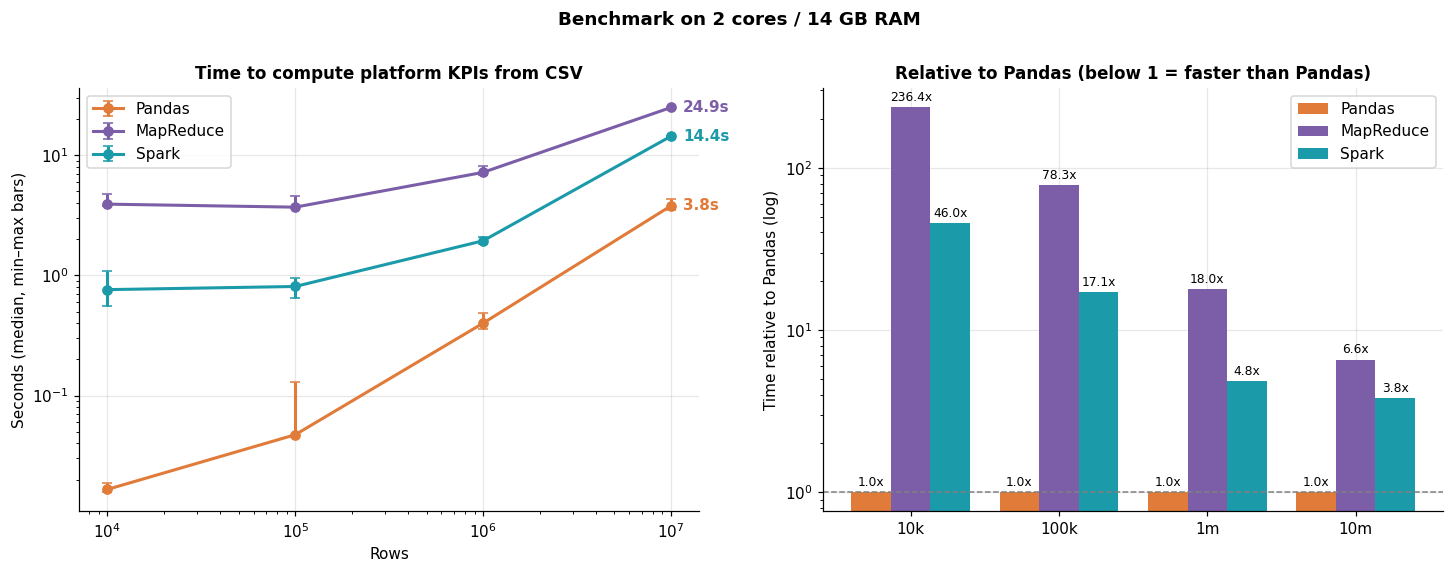

In [10]:
fig, ax = plt.subplots(1, 2, figsize=(16, 5))
for name in ENGINES:
    s = summary[summary.engine == name]
    yerr = [s.median_s - s.min_s, s.max_s - s.median_s]
    ax[0].errorbar(s.rows, s.median_s, yerr=yerr, fmt="o-", lw=2, capsize=3,
                   color=ENGINE_COLORS[name], label=name)
    last = s.iloc[-1]
    ax[0].annotate(f"{last.median_s:.1f}s", (last.rows, last.median_s), textcoords="offset points",
                   xytext=(8, 0), va="center", color=ENGINE_COLORS[name], fontweight="bold")
ax[0].set_xscale("log"); ax[0].set_yscale("log")
ax[0].set_xlabel("Rows"); ax[0].set_ylabel("Seconds (median, min–max bars)")
ax[0].set_title("Time to compute platform KPIs from CSV")
ax[0].legend()

x = np.arange(len(SCALES))
w = 0.8 / len(ENGINES)
for i, name in enumerate(ENGINES):
    s = summary[summary.engine == name].set_index("dataset").reindex(SCALES)
    b = ax[1].bar(x + (i - (len(ENGINES) - 1) / 2) * w, s.vs_pandas, w, color=ENGINE_COLORS[name], label=name)
    ax[1].bar_label(b, fmt="%.1fx", fontsize=8, padding=2)
ax[1].axhline(1, color="grey", lw=1, ls="--")
ax[1].set_xticks(x, list(SCALES))
ax[1].set_yscale("log")
ax[1].set_ylabel("Time relative to Pandas (log)")
ax[1].set_title("Relative to Pandas (below 1 = faster than Pandas)")
ax[1].legend()
fig.suptitle(f"Benchmark on {CORES} cores / {RAM_GB:.0f} GB RAM", fontweight="bold", y=1.02)
viz.save(fig, FIG_DIR, "05_benchmark_main"); plt.show()

## 6. Pandas memory: where does Pandas hit the wall?
Pandas must hold the data in RAM; Spark and MapReduce stream it in pieces.
Measuring how much memory Pandas needs per million rows tells us the largest dataset this machine can handle with Pandas.

,rows,peak_mb,baseline_mb,data_mb
dataset,,,,
10k,10000,109.0,100.0,9.0
100k,100000,127.0,100.0,27.0
1m,1000000,345.0,100.0,244.0
10m,10000000,2425.0,100.0,2325.0


Pandas needs ~239 MB per million rows for this task → about 45 million rows fit in 14 GB RAM.


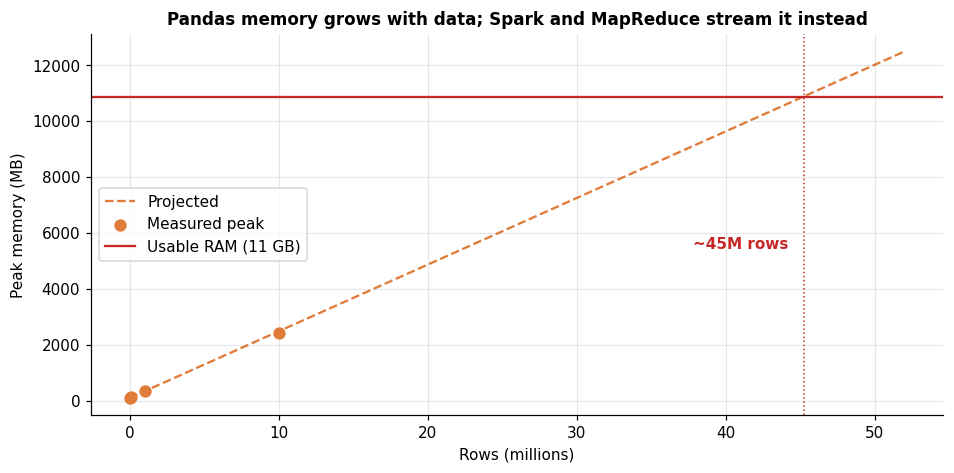

In [11]:
mem = raw[(raw.engine == "Pandas") & raw.peak_mb.notna()].groupby("dataset", sort=False).agg(
    rows=("rows", "first"), peak_mb=("peak_mb", "max"), baseline_mb=("baseline_mb", "max"))
mem["data_mb"] = mem.peak_mb - mem.baseline_mb
big = mem[mem.rows >= 1_000_000]
if big.empty:
    big = mem.tail(1)
mb_per_million = max(float((big.data_mb / (big.rows / 1e6)).mean()), 1.0)
usable_mb = RAM_GB * 1000 * 0.8                     # leave 20% for the OS and Colab
max_rows_m = (usable_mb - mem.baseline_mb.max()) / mb_per_million
mem.to_csv(BENCH_DIR / "05_pandas_memory.csv")
display(mem.round(0))
print(f"Pandas needs ~{mb_per_million:,.0f} MB per million rows for this task "
      f"→ about {max_rows_m:,.0f} million rows fit in {RAM_GB:.0f} GB RAM.")

fig, ax = plt.subplots(figsize=(10, 4.5))
xs = np.linspace(0, max_rows_m * 1.15, 50)
ax.plot(xs, mem.baseline_mb.max() + mb_per_million * xs, "--", color=ENGINE_COLORS["Pandas"], label="Projected")
ax.scatter(mem.rows / 1e6, mem.peak_mb, color=ENGINE_COLORS["Pandas"], zorder=3, s=50, label="Measured peak")
ax.axhline(usable_mb, color="#C62828", lw=1.5, label=f"Usable RAM ({usable_mb / 1000:.0f} GB)")
ax.axvline(max_rows_m, color="#C62828", lw=1, ls=":")
ax.annotate(f"~{max_rows_m:,.0f}M rows", (max_rows_m, usable_mb * 0.5), xytext=(-10, 0),
            textcoords="offset points", ha="right", color="#C62828", fontweight="bold")
ax.set_xlabel("Rows (millions)"); ax.set_ylabel("Peak memory (MB)")
ax.set_title("Pandas memory grows with data; Spark and MapReduce stream it instead")
ax.legend()
viz.save(fig, FIG_DIR, "05_pandas_memory"); plt.show()

## 7. Bonus: each tool with its best file format
MapReduce needs text, but Pandas and Spark can read Parquet.
How much does the file format matter compared with the choice of tool?

CSV        Parquet      
engine  Pandas  Spark  Pandas Spark
dataset                            
10k       0.02   0.76    0.03  0.42
100k      0.05   0.81    0.04  0.45
1m        0.40   1.94    0.14  0.55
10m       3.79  14.39    1.06  2.39

All Parquet runs correct ✓


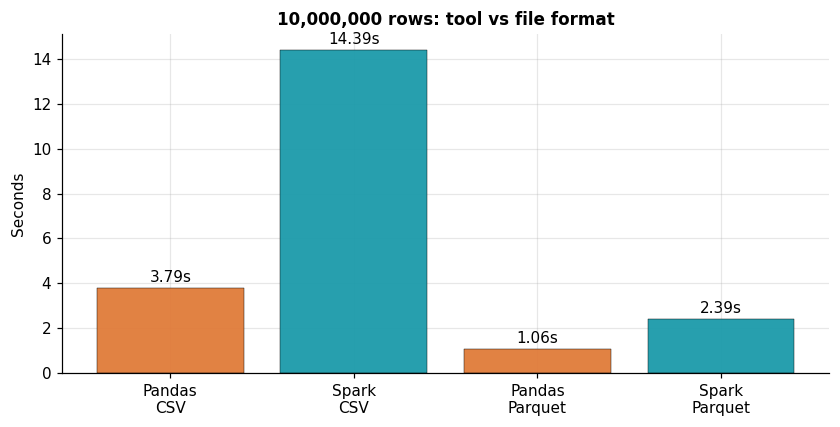

In [12]:
fmt_rec = []
for label in SCALES:
    for rep in range(reps_for(label)):
        for name, fn in (("Pandas", run_pandas), (SPARK_LABEL, run_spark)):
            r = fn(label, "parquet")
            fmt_rec.append({"engine": name, "dataset": label, "rows": SCALES[label], "format": "parquet",
                            "seconds": r["seconds"], "correct": is_correct(r["sums"], label)})
fmt_raw = pd.DataFrame(fmt_rec)
fmt_raw.to_csv(BENCH_DIR / "05_benchmark_parquet_raw.csv", index=False)
parq = fmt_raw.groupby(["dataset", "engine"], sort=False).seconds.median().unstack().reindex(SCALES)
csvt = table[["Pandas", SPARK_LABEL]]
fmt_table = pd.concat({"CSV": csvt, "Parquet": parq}, axis=1).round(2)
display(fmt_table)
print("All Parquet runs correct ✓" if fmt_raw.correct.all() else "⚠️ some Parquet runs incorrect")

big_label = list(SCALES)[-1]
fig, ax = plt.subplots(figsize=(9, 4))
labels = [f"{e}\n{f}" for f in ("CSV", "Parquet") for e in ("Pandas", SPARK_LABEL)]
vals = [fmt_table[(f, e)][big_label] for f in ("CSV", "Parquet") for e in ("Pandas", SPARK_LABEL)]
b = ax.bar(labels, vals, color=[ENGINE_COLORS[e] for _ in range(2) for e in ("Pandas", SPARK_LABEL)],
           alpha=0.95, edgecolor="black", linewidth=0.3)
ax.bar_label(b, fmt="%.2fs", padding=2)
ax.set_ylabel("Seconds"); ax.set_title(f"{SCALES[big_label]:,} rows: tool vs file format")
viz.save(fig, FIG_DIR, "05_format_effect"); plt.show()

## 8. Findings

In [13]:
big, small = list(SCALES)[-1], "10k"
t_big, t_small = table.loc[big], table.loc[small]
fs = lambda v, unit="s", d=1: "failed" if pd.isna(v) else f"{v:.{d}f}{unit}"
growth = {e: table.loc["10m", e] / table.loc["1m", e] for e in ENGINES}
winners = ", ".join(f"{d}: {w}" for d, w in table.fastest.items())
pq_gain = {e: fmt_table[("CSV", e)][big] / fmt_table[("Parquet", e)][big] for e in ("Pandas", SPARK_LABEL)}
failed = raw[(raw.engine == "Pandas") & (raw.status != "ok")]
if len(failed):
    fl = failed.dataset.iloc[0]
    n_fl, n_all = (failed.dataset == fl).sum(), ((raw.engine == "Pandas") & (raw.dataset == fl)).sum()
    pandas_fail = (f" On this machine Pandas **ran out of memory** at {SCALES[fl]:,} rows in {n_fl} of {n_all} runs "
                   f"(the process was killed), while Spark and MapReduce completed every run.")
else:
    pandas_fail = ""
mr_vs_spark = t_big[MR_LABEL] / t_big[SPARK_LABEL]
mr_note = (f"{MR_LABEL} was {mr_vs_spark:.1f}x {'slower' if mr_vs_spark >= 1 else 'faster'} than Spark."
           + (" Hadoop writes intermediate data to disk and starts a new JVM for every job, while Spark plans the "
              "whole job and keeps data in memory." if USE_HADOOP else
              " (MapReduce ran as a pipe simulation here, so this is not a Hadoop timing.)"))

findings = f"""
**Machine:** {CORES} CPU cores, {RAM_GB:.0f} GB RAM{" (Google Colab)" if IN_COLAB else ""} | **Runs:** {len(raw)} timed, {"all correct" if raw.correct.all() else f"{(~raw.correct).sum()} failed"}

1. **Fastest engine by size:** {winners}.
2. **At {SCALES[big]:,} rows:** Pandas {fs(t_big['Pandas'])}, Spark {fs(t_big[SPARK_LABEL])}, {MR_LABEL} {fs(t_big[MR_LABEL])}.
   {mr_note}
3. **Fixed overhead dominates small data:** at 10K rows Pandas took {t_small['Pandas']:.2f}s,
   Spark {t_small[SPARK_LABEL]:.2f}s and {MR_LABEL} {t_small[MR_LABEL]:.2f}s. Distributed engines spend that time
   planning and scheduling, not computing.
4. **Scaling 1M → 10M (10x data):** Pandas {fs(growth['Pandas'], "x")} time, Spark {fs(growth[SPARK_LABEL], "x")},
   {MR_LABEL} {fs(growth[MR_LABEL], "x")}.
5. **Memory is Pandas' real limit:** ~{mb_per_million:,.0f} MB per million rows for this task, so roughly
   **{max_rows_m:,.0f} million rows** fit on this machine.{pandas_fail} Spark and MapReduce stream data in partitions,
   and on a cluster they add machines instead of needing more RAM on one.
6. **File format matters as much as the tool:** at {SCALES[big]:,} rows, Parquet took Pandas
   {fs(fmt_table[("Parquet", "Pandas")][big])} (CSV: {fs(fmt_table[("CSV", "Pandas")][big])}) and Spark
   {fs(fmt_table[("Parquet", SPARK_LABEL)][big])} (CSV: {fs(fmt_table[("CSV", SPARK_LABEL)][big])}).

**Recommendation**
| Situation | Best choice |
|---|---|
| Data fits comfortably in one machine's RAM (here: up to ~{max_rows_m:,.0f}M rows) | **Pandas**: simplest and fast |
| Data larger than RAM, growing, or a scheduled production pipeline | **Spark**: scales out, SQL, optimiser |
| New projects | **Not MapReduce**: Spark replaced it, but its map → shuffle → reduce model underlies all of these tools |

*Caveat:* this is a single {CORES}-core machine. Spark and MapReduce are built for clusters, where they spread work over many machines;
here they pay coordination costs without that benefit. The results show single-machine behaviour, not cluster performance.
"""
(REP_DIR / "05_findings.md").write_text(findings)
display(Markdown(findings))

env = {"cores": CORES, "ram_gb": round(RAM_GB, 1), "python": platform.python_version(), "pandas": pd.__version__,
       "spark": spark.version, "mapreduce": f"Hadoop {HADOOP_VERSION}" if USE_HADOOP else "pipe simulation",
       "repeats": REPEATS, "datasets": list(SCALES), "colab": IN_COLAB}
(BENCH_DIR / "05_environment.json").write_text(json.dumps(env, indent=2))
spark.stop()


**Machine:** 2 CPU cores, 14 GB RAM (Google Colab) | **Runs:** 36 timed, all correct

1. **Fastest engine by size:** 10k: Pandas, 100k: Pandas, 1m: Pandas, 10m: Pandas.
2. **At 10,000,000 rows:** Pandas 3.8s, Spark 14.4s, MapReduce 24.9s.
   MapReduce was 1.7x slower than Spark. Hadoop writes intermediate data to disk and starts a new JVM for every job, while Spark plans the whole job and keeps data in memory.
3. **Fixed overhead dominates small data:** at 10K rows Pandas took 0.02s,
   Spark 0.76s and MapReduce 3.91s. Distributed engines spend that time
   planning and scheduling, not computing.
4. **Scaling 1M → 10M (10x data):** Pandas 9.5x time, Spark 7.4x,
   MapReduce 3.5x.
5. **Memory is Pandas' real limit:** ~239 MB per million rows for this task, so roughly
   **45 million rows** fit on this machine. Spark and MapReduce stream data in partitions,
   and on a cluster they add machines instead of needing more RAM on one.
6. **File format matters as much as the tool:** at 10,000,000 rows, Parquet took Pandas
   1.1s (CSV: 3.8s) and Spark
   2.4s (CSV: 14.4s).

**Recommendation**
| Situation | Best choice |
|---|---|
| Data fits comfortably in one machine's RAM (here: up to ~45M rows) | **Pandas**: simplest and fast |
| Data larger than RAM, growing, or a scheduled production pipeline | **Spark**: scales out, SQL, optimiser |
| New projects | **Not MapReduce**: Spark replaced it, but its map → shuffle → reduce model underlies all of these tools |

*Caveat:* this is a single 2-core machine. Spark and MapReduce are built for clusters, where they spread work over many machines;
here they pay coordination costs without that benefit. The results show single-machine behaviour, not cluster performance.


## ✅ Notebook 05 complete

**Saved:** raw timings, summary, memory and environment details in `outputs/benchmarks/05_*`; charts in `outputs/figures/05_*`;
findings in `outputs/reports/05_findings.md`.

**Next: Notebook 06, Recommendation engine.** Back to the business question: how should the next Rs. 1,000,000 be split across platforms?